<a href="https://colab.research.google.com/github/sneha121083-dotcom/Heart_Disease_Prediction_Model/blob/main/Heart_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the uploaded dataset
df = pd.read_csv('heart.csv')

# Check the first 5 rows, shape, and missing values
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
display(df.head())


Dataset Shape: (1025, 14)

Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Remove duplicates
df.drop_duplicates(inplace=True)
print("Shape after removing duplicates:", df.shape)

# 2. Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# 3. Split data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data successfully scaled and split!")


Shape after removing duplicates: (302, 14)
Data successfully scaled and split!


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Initialize models
lr_model = LogisticRegression(random_state=42)
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train models
lr_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train_scaled, y_train)

# Make predictions
lr_pred = lr_model.predict(X_test_scaled)
dt_pred = dt_model.predict(X_test_scaled)

# Print detailed reports
print("=== LOGISTIC REGRESSION ===")
print(classification_report(y_test, lr_pred))

print("=== DECISION TREE ===")
print(classification_report(y_test, dt_pred))


=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61

=== DECISION TREE ===
              precision    recall  f1-score   support

           0       0.69      0.71      0.70        28
           1       0.75      0.73      0.74        33

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61



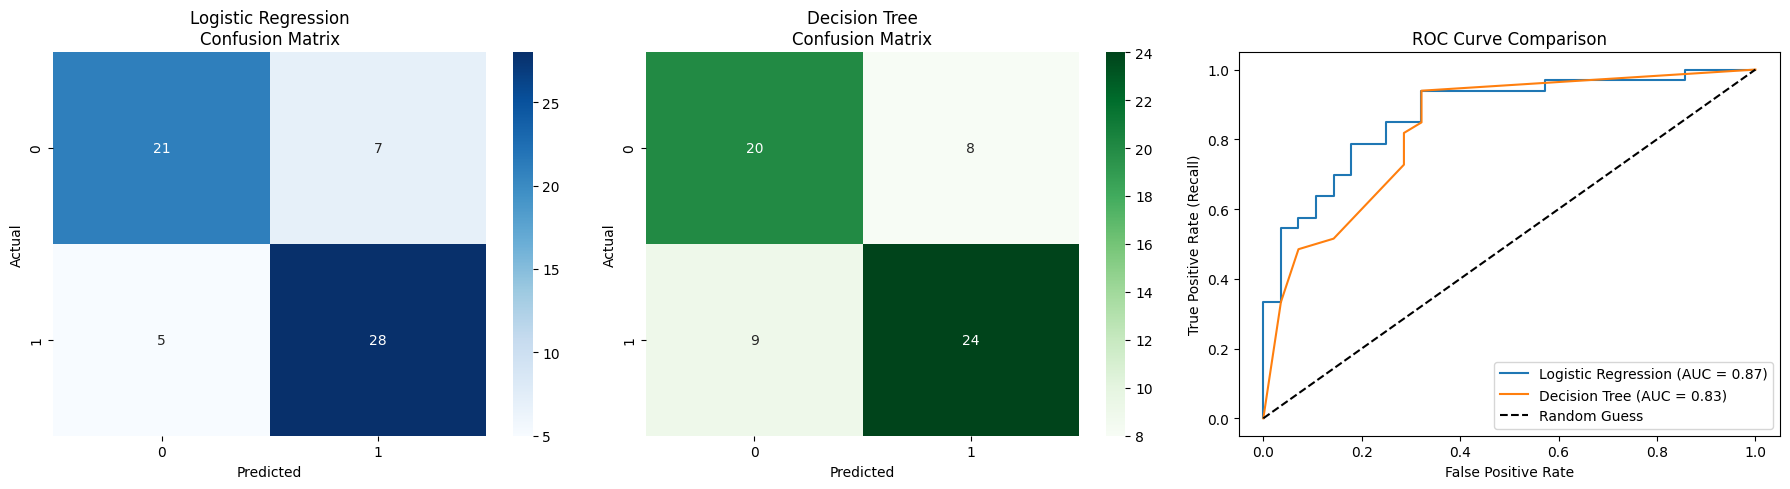

In [6]:
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Get predicted probabilities for ROC curve
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]
dt_prob = dt_model.predict_proba(X_test_scaled)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Logistic Regression Confusion Matrix
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Logistic Regression\nConfusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# 2. Decision Tree Confusion Matrix
sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("Decision Tree\nConfusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# 3. ROC Curve Comparison
for name, prob in [("Logistic Regression", lr_prob), ("Decision Tree", dt_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

axes[2].plot([0, 1], [0, 1], 'k--', label="Random Guess")
axes[2].set_title("ROC Curve Comparison")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate (Recall)")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.savefig("evaluation_charts.png", dpi=300)
plt.show()

In [8]:
# Example new patient data (13 features matching X columns)
sample_patient = X_test.iloc[[0]]
sample_scaled = scaler.transform(sample_patient)

prediction = lr_model.predict(sample_scaled)
# Corrected: index the first row [0], and then grab the class 1 probability [1]
probability = lr_model.predict_proba(sample_scaled)[0, 1]

print(f"Prediction: {'Heart Disease Likely (1)' if prediction[0] == 1 else 'No Heart Disease (0)'}")
print(f"Risk Probability: {probability * 100:.2f}%")

Prediction: No Heart Disease (0)
Risk Probability: 18.54%
